Code pipeline:
- read video from same folder
- convert video to grayscale
- take average grayscale value of each frame
- plot value against time
- extract pulse rate using f = 1/T, using Fourier transform to get highest intensity frequency

In [2]:
#import libraries 
import numpy as np 
import matplotlib.pyplot as plt 


In [3]:
import cv2
print(cv2.__version__)

5.0.0


In [4]:
from videoreader import VideoReader #imports video reading extension


In [5]:
#select video path 
video = 'data/video_of_finger_compressed.mp4'
cap = cv2.VideoCapture(video)
vr = VideoReader('data/video_of_finger_compressed.mp4')
print(vr)  # prints video_file_name, number of frames, frame rate and frame size

data/video_of_finger_compressed.mp4 with 1852 frames of size (1920, 1080, 3) at 29.97 fps


In [6]:
print(cap.get(cv2.CAP_PROP_FRAME_COUNT))
fr1 = vr[1] #testing format of array

1852.0


In [7]:
frames = []
while cap.isOpened():
    ret, frame = cap.read() #reads video frame by frame
    if not ret:
        break  # stops video

  
    grayscale = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY) # converts video to grayscale

    
    avg = np.mean(grayscale) # finds average intensity per frame
    frames.append(avg) # puts intensities into an array

cap.release()

print(frames)




[np.float64(55.56969618055555), np.float64(55.20321228780864), np.float64(53.912096354166664), np.float64(52.67570891203704), np.float64(51.764076967592594), np.float64(51.26329668209876), np.float64(50.89879195601852), np.float64(50.81197868441358), np.float64(50.91978973765432), np.float64(51.07041618441358), np.float64(51.31127748842592), np.float64(51.58739245756173), np.float64(51.70134645061729), np.float64(51.79250964506173), np.float64(51.86058256172839), np.float64(51.988694058641975), np.float64(52.154769483024694), np.float64(52.506641589506174), np.float64(52.92479938271605), np.float64(53.363187692901235), np.float64(53.88601755401235), np.float64(54.30286747685185), np.float64(54.783538773148145), np.float64(55.05597222222222), np.float64(55.35742959104938), np.float64(55.58080777391975), np.float64(55.49865451388889), np.float64(54.26457899305556), np.float64(52.882377025462965), np.float64(52.157822627314815), np.float64(51.52648678626543), np.float64(51.1574537037037),

In [8]:
cap = cv2.VideoCapture(video)

fr = cap.get(cv2.CAP_PROP_FRAME_COUNT) # get number of frames
np.int32(fr) # change frames to integer values
frar = np.arange(1,fr+1) # make an array from 1 - frame number
print(frar)


[1.000e+00 2.000e+00 3.000e+00 ... 1.850e+03 1.851e+03 1.852e+03]


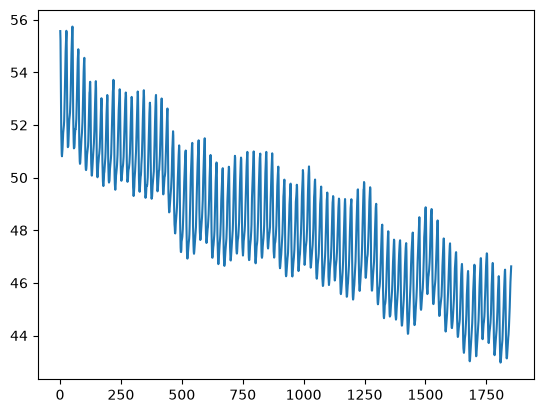

In [9]:
plt.plot(frar, frames) # plot intensity against frame number

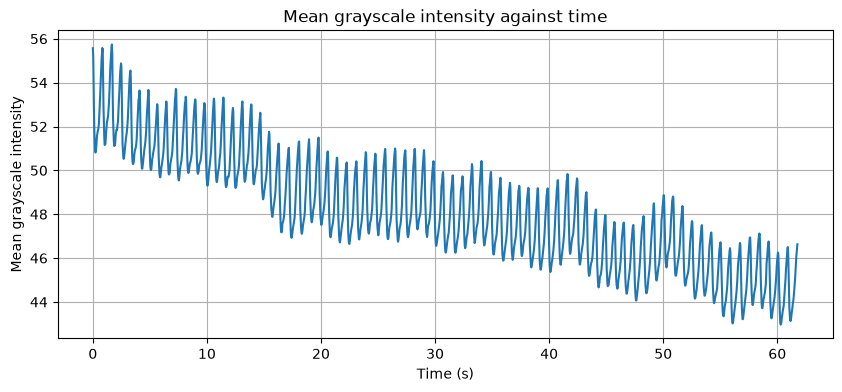

In [57]:
# Reopen the video again as it was released earlier
cap = cv2.VideoCapture(video)

# Obtain the sampling frequency (number of frames per second)
fs = cap.get(cv2.CAP_PROP_FPS) # Sampling frequency
N = len(frames) # Obtain the total number of frames by counting the grayscale values 

# Convert frame numbers into their corresponding times in seconds
# by dividing them by the number of frames recorded per second
time = np.arange(N) / fs # Time array in seconds



# Plot the mean grayscale intensity against time 
plt.figure(figsize=(10,4))
plt.plot(time, frames)
plt.xlabel("Time (s)")
plt.ylabel("Mean grayscale intensity")
plt.title("Mean grayscale intensity against time")
plt.grid()
plt.show()

cap.release() # Close the video capture object

In [11]:
# Calculate FFT of grayscale signal
signal_fft = np.fft.fft(frames)

#frequency array
frequencies = np.fft.fftfreq(N, 1/fs)
print(frequencies)


[ 0.          0.01618252  0.03236504 ... -0.04854756 -0.03236504
 -0.01618252]


In [ ]:
# Calculate the power spectrum, normalize
signal_power = np.abs(signal_fft)**2 / N

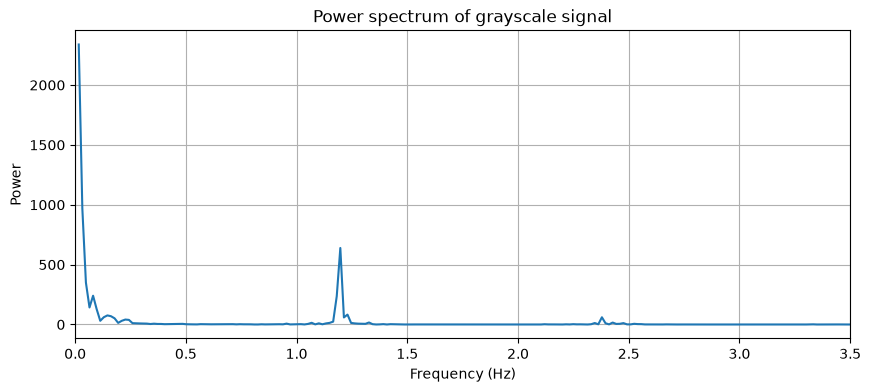

In [40]:
# Select positive frequencies 
mask = (frequencies > 0)

# Plot power spectrum
plt.figure(figsize=(10,4))
plt.plot(frequencies[mask], signal_power[mask])
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power")
plt.title("Power spectrum of grayscale signal")
plt.xlim(0,3.5) # Limit the displayed frequency range to 0–3.5 Hz
plt.grid()
plt.show()


In [48]:
f_mask = frequencies > 0.5

pulse_index = np.argmax(signal_power[f_mask]) # find the index of highest intensity
pulse_f = frequencies[f_mask][pulse_index] # find the frequency at that index

print(f'The frequency of the pulse is {round(pulse_f, 2)} Hz') # print the pulse frequency, to two decimal places

The frequency of the pulse is 1.2 Hz


In [60]:
hr = pulse_f * 60
print(f'The heart rate is {round(hr, 0)} beats per minute.')

The heart rate is 72.0 beats per minute.
